# UTS Data Mining — Klasifikasi Kualitas Anggur (*Wine Quality*)

**Nama: Fathir Rizwa**

**NIM: 2404010025**

**Tujuan:** memprediksi kolom `quality` (skala 0–10) untuk `data_testing.csv` memakai model klasifikasi yang dilatih dari `data_training.csv`.

**Alur kerja (8 langkah):**
1. *Import library*
2. Membaca file
3. EDA + visualisasi
4. *Preprocessing* (*missing*, duplikat, tipe data, *scaling*, *feature engineering*)
5. Pelatihan banyak model (split 80/20 + cross-validation)
6. Tabel perbandingan model otomatis
7. Evaluasi, tuning, dan pemilihan model terbaik
8. Prediksi data testing dan penyimpanan hasil

> Setiap langkah punya **penjelasan sintaks** (sebelum kode) dan **interpretasi output** (sesudah kode).

## **1. *Import Library***

**Penjelasan sintaks**
- `pandas`, `numpy`: mengolah tabel dan angka.
- `matplotlib`, `seaborn`: membuat grafik.
- `sklearn` (*scikit-learn*): pustaka utama machine learning (model, split data, *cross-validation*, metrik).
- `Pipeline`: merangkai langkah (imputasi → scaling → model) menjadi satu objek, sehingga proses yang sama otomatis dipakai saat *training* dan *testing*, dan **tidak terjadi kebocoran data** saat *cross-validation*.
- `try ... except ImportError`: XGBoost dan LightGBM bersifat opsional. Jika terpasang di komputermu, keduanya otomatis ikut dilombakan. Jika belum, skrip tetap jalan (pasang dengan `pip install xgboost lightgbm`).
- `SEED = 42`: angka acak dikunci supaya hasil bisa diulang (*reproducible*).
- **`NIM3`**: 3 digit terakhir NIM (dipakai untuk nama file hasil), karena dipakai untuk nama file hasil.

In [1]:
import time
import warnings
import joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_score,
                                     RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score,
                             cohen_kappa_score, classification_report,
                             confusion_matrix)

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier,
                              HistGradientBoostingClassifier,
                              AdaBoostClassifier, BaggingClassifier,
                              VotingClassifier)
from sklearn.neural_network import MLPClassifier

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEED = 42
NIM3 = "025"   # <-- 3 digit terakhir NIM

print("XGBoost terpasang :", HAS_XGB)
print("LightGBM terpasang:", HAS_LGBM)

XGBoost terpasang : True
LightGBM terpasang: True


## **2. Membaca File**

In [2]:
DATA_DIR = next((d for d in (Path("UTS_DatMin"), Path(".")) if (d / "data_training.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("data_training.csv tidak ditemukan. Taruh notebook di folder yang berisi UTS_DatMin/.")

df_train = pd.read_csv(DATA_DIR / "data_training.csv")
df_test = pd.read_csv(DATA_DIR / "data_testing.csv")

sample_path = DATA_DIR / "hasilprediksi_3digitNIMterakhir.csv"
sample_sub = pd.read_csv(sample_path, sep=";") if sample_path.exists() else None

print("Data training:", df_train.shape)
print("Data testing :", df_test.shape)
print("Format contoh hasil:", None if sample_sub is None else list(sample_sub.columns))
print("\nKolom hanya ada di training:", set(df_train.columns) - set(df_test.columns))
display(df_train.head())

Data training: (857, 13)
Data testing : (286, 12)
Format contoh hasil: None

Kolom hanya ada di training: {'quality'}


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


**Interpretasi:**
- Data *training* berisi **857 baris × 13 kolom**; data testing **286 baris × 12 kolom**.
- Satu-satunya kolom yang hanya ada di *training* adalah `quality` (target yang harus diprediksi).
- Selain `quality`, ada 11 fitur kimiawi numerik dan kolom `Id` (penanda baris, bukan fitur).
- File contoh hasil berformat dua kolom: `Id` dan `Quality`.

## **3. *Exploratory Data Analysis* (EDA)**

EDA = mengenal data sebelum memodelkan: tipe data, ringkasan statistik, sebaran, *outlier*, dan hubungan antar variabel.

### **3.1 Struktur dan ringkasan statistik**
**Penjelasan sintaks**
- `.info()` menampilkan tipe tiap kolom dan jumlah nilai terisi.
- `.describe()` menghitung rata-rata, simpangan baku (std), min, kuartil, dan max. `.T` memutar tabel agar mudah dibaca.

In [3]:
FEATURES = [c for c in df_train.columns if c not in ("quality", "Id")]
TARGET = "quality"

df_train.info()
print()
display(df_train[FEATURES].describe().T.round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  Id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 87.2 KB



,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.262,1.702,4.600,7.100,7.900,9.100,15.600
volatile acidity,857.0,0.529,0.179,0.120,0.395,0.520,0.640,1.580
citric acid,857.0,0.267,0.195,0.000,0.090,0.250,0.420,1.000
residual sugar,857.0,2.506,1.294,0.900,1.900,2.200,2.600,15.500
chlorides,857.0,0.087,0.049,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,857.0,15.783,10.300,1.000,7.000,14.000,21.000,68.000
total sulfur dioxide,857.0,45.978,31.692,6.000,21.000,38.000,63.000,278.000
density,857.0,0.997,0.002,0.990,0.996,0.997,0.998,1.003
pH,857.0,3.313,0.152,2.740,3.210,3.310,3.400,4.010
sulphates,857.0,0.657,0.167,0.390,0.550,0.620,0.730,2.000


**Interpretasi:**
- Semua kolom terisi penuh (857 *non-null* di setiap kolom), jadi **tidak ada *missing value***; semua fitur bertipe numerik.
- **Skala antar fitur sangat berbeda.** `total sulfur dioxide` bernilai 6–278 (rata-rata 46), sedangkan `density` hampir konstan di sekitar 0.997 (std 0.002). Perbedaan ini mengganggu model linear/jarak (Logistic Regression, KNN, SVM), sehingga ***scaling* diperlukan**; model pohon tidak terpengaruh.
- `quality` bernilai 3–8 dengan rata-rata 5.65, artinya kebanyakan anggur bernilai menengah.

### **3.2 Sebaran target** (`quality`)
**Penjelasan sintaks**
- `.value_counts().sort_index()` menghitung banyaknya sampel tiap nilai kualitas, diurutkan dari kecil ke besar.
- `ax.bar(...)` menggambar diagram batang; `ax.text(...)` menuliskan jumlah dan persentase di atas batang.
- Kelas yang timpang (*imbalanced*) berpengaruh pada pilihan metrik: akurasi saja bisa menipu.

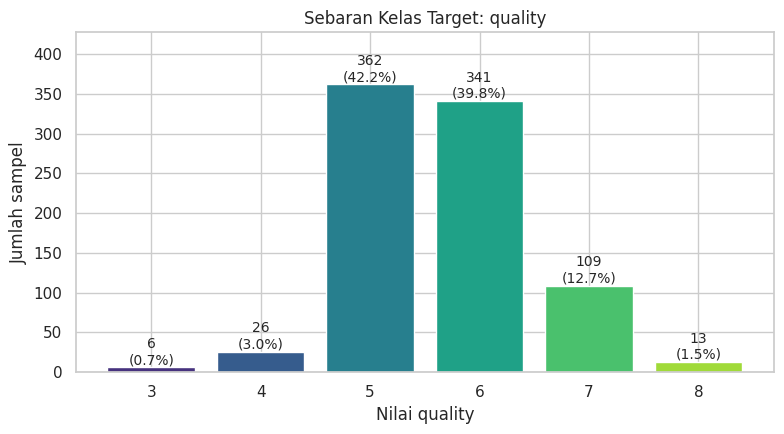

Rasio kelas terbanyak : kelas terkecil = 60.3 : 1


In [4]:
counts = df_train[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index.astype(str), counts.values, color=sns.color_palette("viridis", len(counts)))
for b, c, p in zip(bars, counts.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 4, f"{c}\n({p:.1f}%)", ha="center", fontsize=10)
ax.set_title("Sebaran Kelas Target: quality")
ax.set_xlabel("Nilai quality")
ax.set_ylabel("Jumlah sampel")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.show()

print("Rasio kelas terbanyak : kelas terkecil =", round(counts.max() / counts.min(), 1), ": 1")

**Interpretasi:**
- Kelas **5 (42.2%)** dan **6 (39.8%)** mendominasi, total sekitar 82% data.
- Kelas ekstrem sangat langka: kualitas 3 hanya **6 sampel (0.7%)** dan kualitas 8 hanya **13 sampel (1.5%)**. Rasio kelas terbesar : terkecil sekitar **60 : 1**.
- Akibatnya, **akurasi saja menyesatkan**: model yang hanya menebak 5 atau 6 sudah mendapat akurasi sekitar 40%+. Karena itu evaluasi juga memakai *balanced accuracy*, *F1 macro*, dan *Cohen's Kappa*.
- Kelas langka (3, 4, 8) akan sulit diprediksi karena contohnya sangat sedikit.

### **3.2b Pemeriksaan kualitas data: *missing value* dan duplikat**
**Penjelasan sintaks**
- `.isna().sum()` menghitung sel kosong **per kolom**.
- `.duplicated()` menandai baris yang isinya sama dengan baris sebelumnya. Perhatikan dua versi: **dengan** kolom `Id` dan **tanpa** `Id`. Karena `Id` selalu unik, pemeriksaan yang menyertakan `Id` tidak akan pernah menemukan duplikat, padahal isi kimianya bisa sama persis.
- Tabel terakhir menghitung duplikat per kelas kualitas untuk melihat apakah duplikat terkonsentrasi di kelas tertentu.

In [5]:
miss = df_train.isna().sum().to_frame("missing_train").join(df_test.isna().sum().to_frame("missing_test"), how="outer").fillna(0).astype(int)
display(miss)

dup_with_id = df_train.duplicated().sum()
dup_mask_eda = df_train.drop(columns="Id").duplicated(keep="first")
print(f"Duplikat dengan kolom Id   : {dup_with_id}")
print(f"Duplikat tanpa kolom Id    : {dup_mask_eda.sum()} ({dup_mask_eda.mean()*100:.1f}%)")

dup_by_class = pd.DataFrame({"jumlah_baris": df_train[TARGET].value_counts().sort_index(),
                             "duplikat": df_train.loc[dup_mask_eda, TARGET].value_counts().sort_index()}).fillna(0).astype(int)
dup_by_class["persen_duplikat"] = (dup_by_class["duplikat"] / dup_by_class["jumlah_baris"] * 100).round(1)
display(dup_by_class)

,missing_train,missing_test
Id,0,0
alcohol,0,0
chlorides,0,0
citric acid,0,0
density,0,0
fixed acidity,0,0
free sulfur dioxide,0,0
pH,0,0
quality,0,0
residual sugar,0,0


Duplikat dengan kolom Id   : 0
Duplikat tanpa kolom Id    : 76 (8.9%)


,jumlah_baris,duplikat,persen_duplikat
quality,,,
3,6,0,0.0
4,26,0,0.0
5,362,32,8.8
6,341,31,9.1
7,109,12,11.0
8,13,1,7.7


**Interpretasi:**
- Semua kolom terisi lengkap di *training* maupun *testing*: ***missing value* = 0**.
- Pemeriksaan duplikat **dengan `Id` menghasilkan 0**, tetapi **tanpa `Id` menghasilkan 76 baris (8.9%)**. Jadi `Id` yang selalu unik menyembunyikan duplikat. Pemeriksaan yang hanya memakai `.duplicated()` biasa akan menyimpulkan "tidak ada duplikat", padahal ada 76 sampel kimia yang kembar.
- Duplikat tersebar merata di kelas 5, 6, 7 (sekitar 9–11% tiap kelas), tidak terkonsentrasi di satu kelas, sehingga menghapusnya tidak mengubah proporsi kelas secara berarti.

### **3.3 Distribusi tiap fitur (histogram + kurva KDE)**
**Penjelasan sintaks**
- `plt.subplots(3, 4)` membuat kisi 3×4 grafik; `axes.ravel()` meratakannya agar bisa di-*loop*.
- `sns.histplot(..., kde=True)` menggambar histogram dengan garis kepadatan (KDE).
- `.skew()` = kemencengan. Positif → ekor panjang ke kanan; |skew| > 1 dianggap sangat miring.

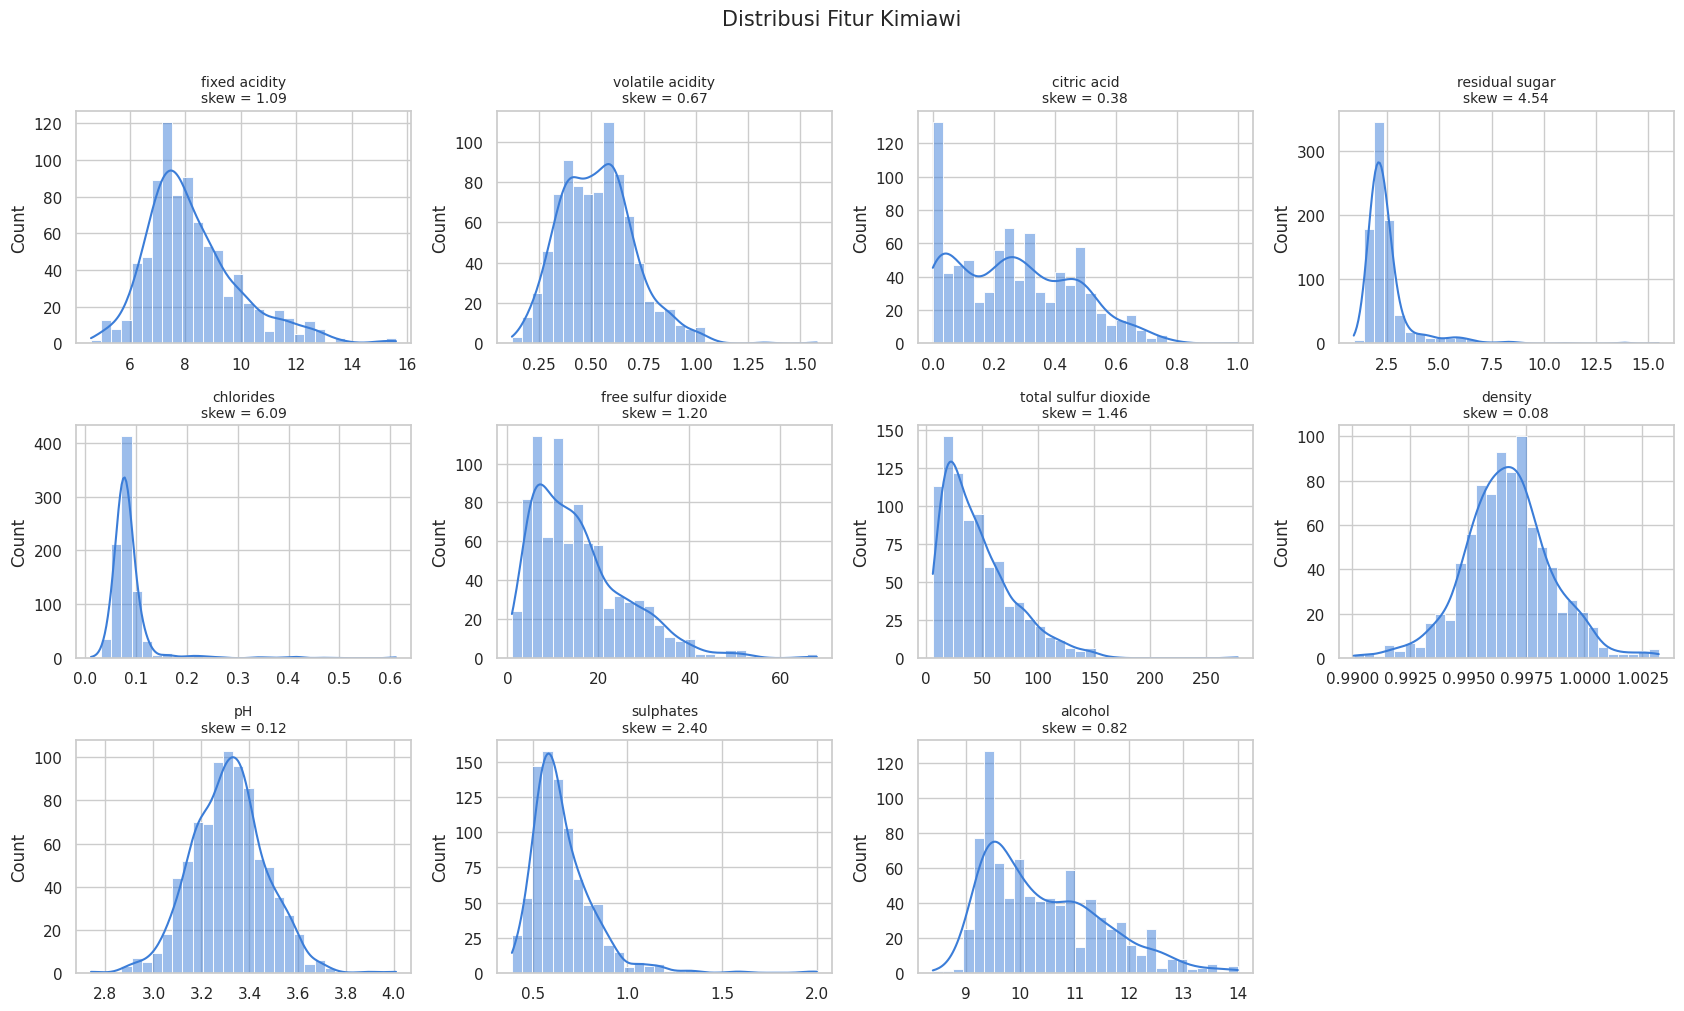

,skewness
chlorides,6.09
residual sugar,4.54
sulphates,2.40
total sulfur dioxide,1.46
free sulfur dioxide,1.20
fixed acidity,1.09
alcohol,0.82
volatile acidity,0.67
citric acid,0.38
pH,0.12


In [6]:
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df_train[col], kde=True, bins=30, ax=ax, color="#3b7dd8")
    ax.set_title(f"{col}\nskew = {df_train[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Distribusi Fitur Kimiawi", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

display(df_train[FEATURES].skew().sort_values(ascending=False).round(2).to_frame("skewness"))

**Interpretasi:**
- Fitur yang **sangat miring ke kanan**: `chlorides` (skew 6.09), `residual sugar` (4.54), `sulphates` (2.40). Sebagian besar sampel bernilai kecil, dengan segelintir nilai sangat besar.
- Fitur yang hampir simetris/normal: `density` (0.08) dan `pH` (0.12).
- `citric acid` menumpuk di nilai 0 (banyak anggur tanpa asam sitrat).
- Kemencengan tidak masalah bagi model pohon. Untuk model linear/jarak, ekor panjang bisa mendominasi jarak, sehingga scaling tetap dipakai.

### **3.4 Deteksi *outlier* (boxplot + aturan IQR)**
**Penjelasan sintaks**
- Boxplot: kotak = 50% data tengah (Q1–Q3), garis = median, titik di luar "kumis" = kandidat *outlier*.
- Aturan IQR: nilai di luar `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` dianggap *outlier*. `quantile(0.25)` dan `quantile(0.75)` memberi Q1 dan Q3.

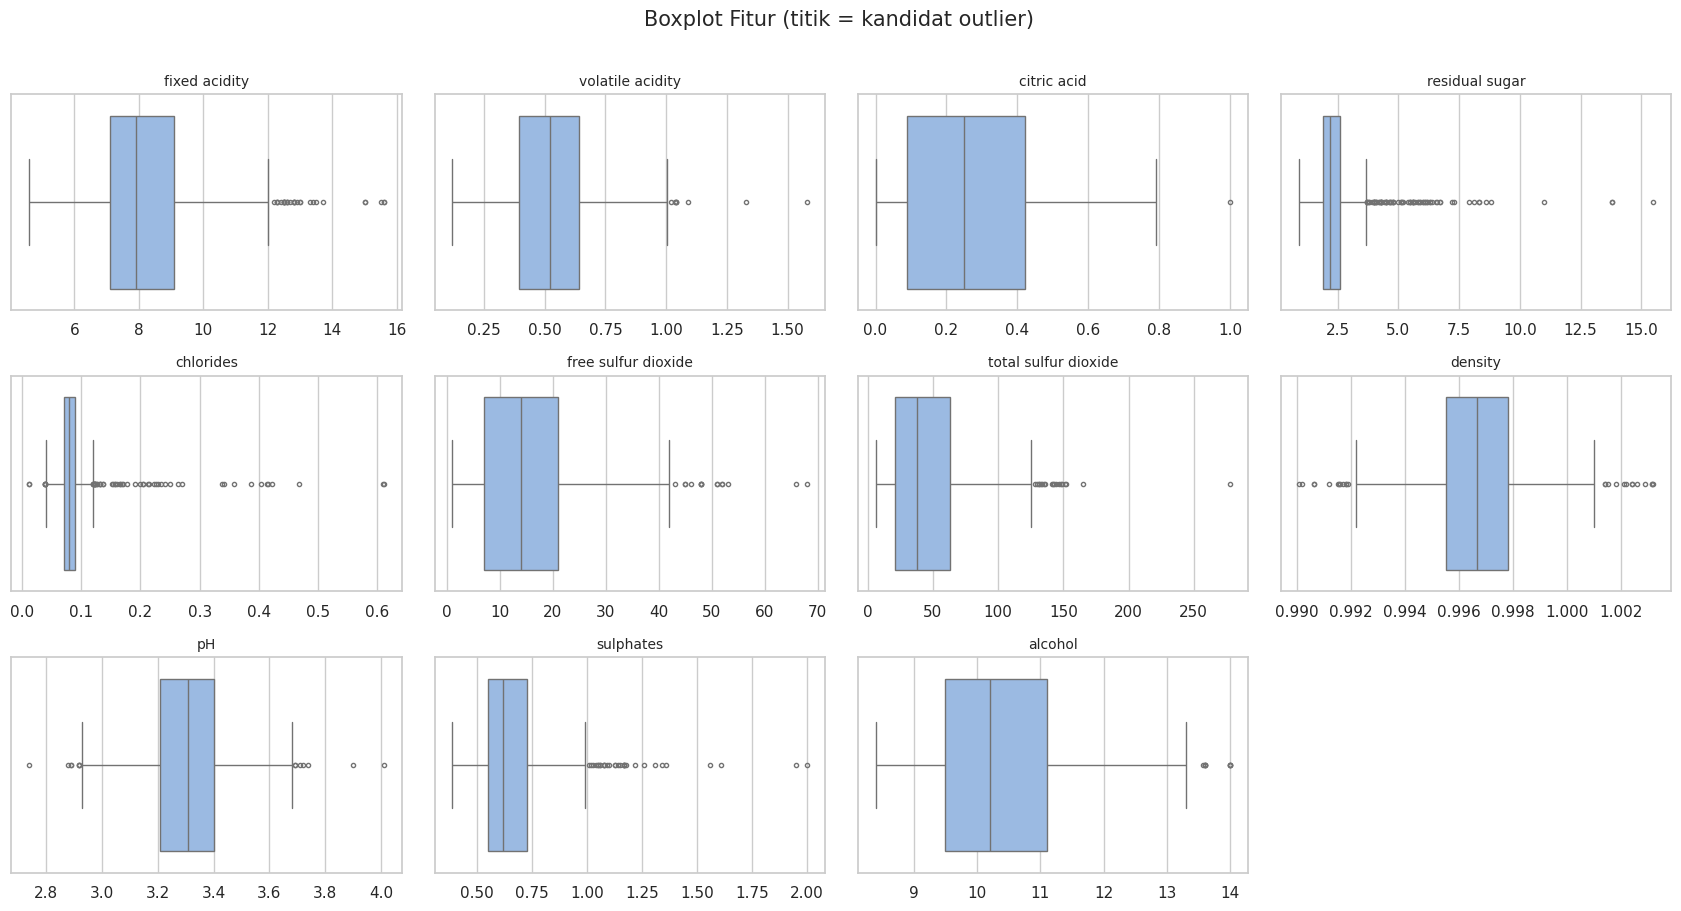

,jumlah_outlier,persen
residual sugar,76,8.87
chlorides,59,6.88
sulphates,31,3.62
fixed acidity,30,3.50
density,25,2.92
total sulfur dioxide,19,2.22
free sulfur dioxide,15,1.75
pH,14,1.63
alcohol,9,1.05
volatile acidity,8,0.93


In [7]:
fig, axes = plt.subplots(3, 4, figsize=(17, 9))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(x=df_train[col], ax=ax, color="#8fb8ee", fliersize=3)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Boxplot Fitur (titik = kandidat outlier)", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

q1, q3 = df_train[FEATURES].quantile(0.25), df_train[FEATURES].quantile(0.75)
iqr = q3 - q1
is_out = (df_train[FEATURES] < q1 - 1.5 * iqr) | (df_train[FEATURES] > q3 + 1.5 * iqr)
out_table = pd.DataFrame({"jumlah_outlier": is_out.sum(), "persen": (is_out.mean() * 100).round(2)})
display(out_table.sort_values("jumlah_outlier", ascending=False))

**Interpretasi:**
- *Outlier* terbanyak ada pada `residual sugar` (76 sampel, 8.87%) dan `chlorides` (59 sampel, 6.88%), diikuti `sulphates` (3.62%) dan `fixed acidity` (3.50%). Ini konsisten dengan fitur yang miring pada histogram.
- Nilai-nilai ini adalah pengukuran kimia yang nyata (anggur manis atau sangat asin memang ada), bukan kesalahan input. **Keputusan: *outlier* dipertahankan**, karena data sudah sedikit dan model pohon tahan terhadap *outlier*.

### **3.5 Korelasi antar variabel**
**Penjelasan sintaks**
- `.corr()` menghitung korelasi Pearson (−1 s.d. +1) antar semua kolom.
- `sns.heatmap(..., annot=True)` menggambar peta panas dengan angka. `np.triu(...)` menyembunyikan segitiga atas yang duplikat.
- Grafik kedua mengurutkan korelasi setiap fitur terhadap `quality`.

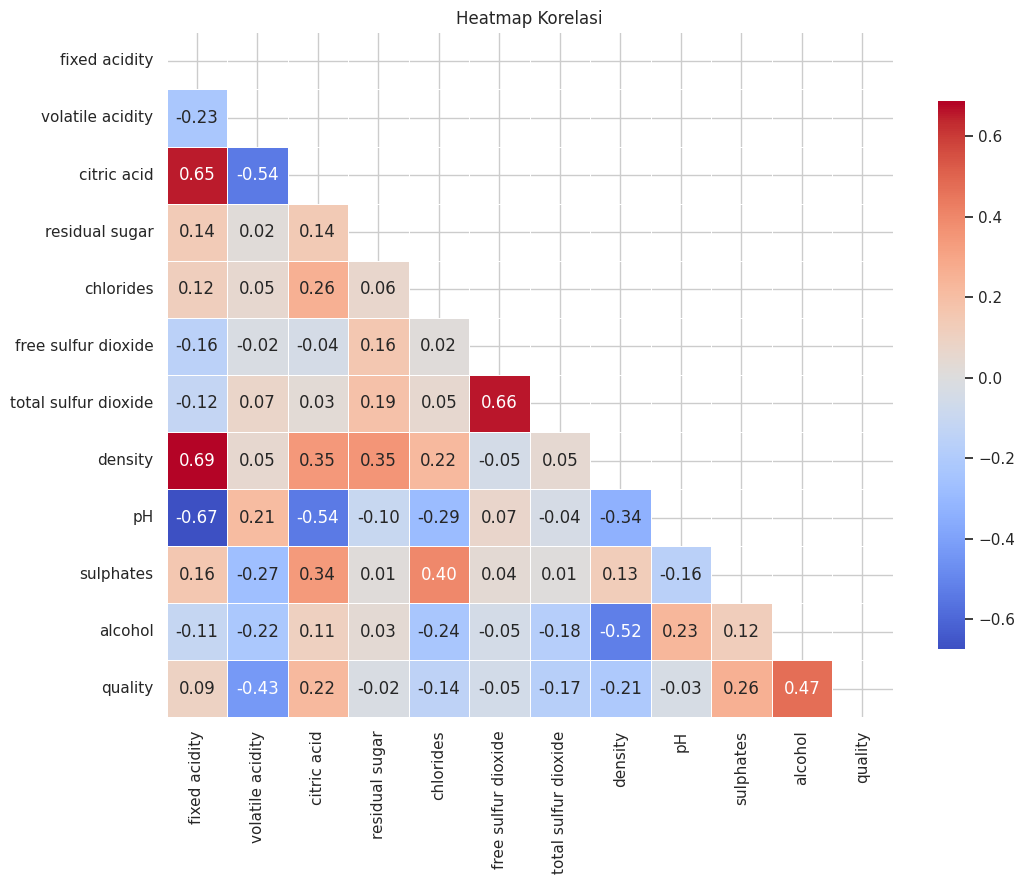

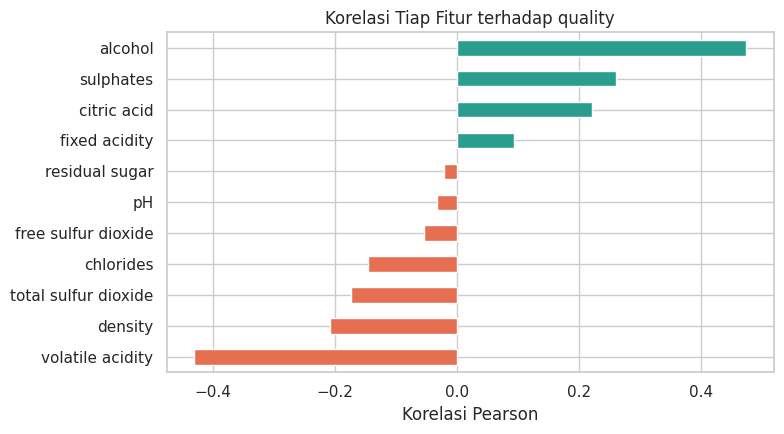

In [8]:
corr = df_train[FEATURES + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Heatmap Korelasi")
plt.tight_layout()
plt.show()

corr_q = corr[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(8, 4.5))
corr_q.plot(kind="barh", color=np.where(corr_q > 0, "#2a9d8f", "#e76f51"))
plt.title("Korelasi Tiap Fitur terhadap quality")
plt.xlabel("Korelasi Pearson")
plt.tight_layout()
plt.show()

**Interpretasi (korelasi terhadap `quality`):**
- Berkorelasi **positif**: `alcohol` (+0.47, terkuat), `sulphates` (+0.26), `citric acid` (+0.22). Anggur dengan alkohol lebih tinggi cenderung bernilai lebih baik.
- Berkorelasi **negatif**: `volatile acidity` (−0.43, terkuat), `density` (−0.21), `total sulfur dioxide` (−0.17). Asam volatil tinggi (aroma seperti cuka) menurunkan kualitas.
- Tidak ada fitur dengan korelasi di atas 0.5, jadi hubungan fitur–kualitas hanya **lemah sampai sedang**. Ini menjelaskan mengapa akurasi tidak akan mendekati 100%.

**Antar fitur (multikolinearitas):**

`fixed acidity` berkorelasi kuat dengan `density` (0.69), `pH` (−0.67), dan `citric acid` (0.65); `free` dan `total sulfur dioxide` juga berkorelasi (0.66). Ini wajar secara kimia dan tidak merugikan model pohon; untuk Logistic Regression, bisa membuat koefisien kurang stabil.

### **3.6 Fitur terpenting vs kualitas**
**Penjelasan sintaks**
- `corr_q.abs().sort_values(...).index[:6]` mengambil 6 fitur dengan korelasi terkuat terhadap `quality`.
- `sns.boxplot(x="quality", y=fitur)` memperlihatkan bagaimana nilai fitur bergeser untuk tiap tingkat kualitas.

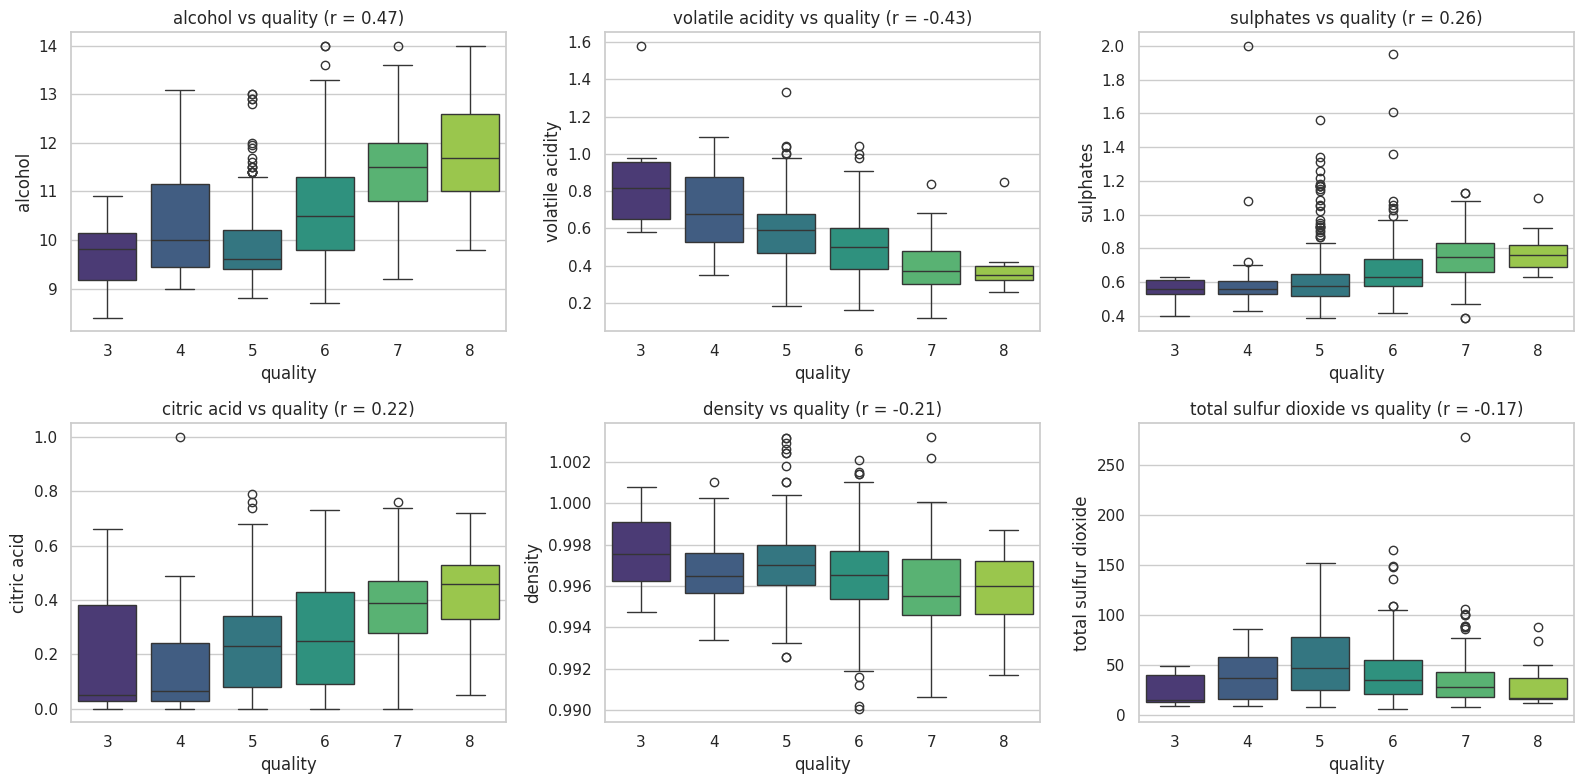

In [9]:
top6 = corr_q.abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), top6):
    sns.boxplot(data=df_train, x=TARGET, y=col, ax=ax, palette="viridis")
    ax.set_title(f"{col} vs quality (r = {corr_q[col]:.2f})")
plt.tight_layout()
plt.show()

**Interpretasi:**

pola naiknya kualitas terlihat jelas pada median fitur. Dari kualitas 5 ke 7, median `alcohol` naik dari 9.6 ke 11.5, `volatile acidity` turun dari 0.59 ke 0.37, dan `sulphates` naik dari 0.58 ke 0.75. Pola ini yang akan dimanfaatkan model. Namun kotak-kotak antar kualitas bertumpang tindih lebar, jadi tidak ada satu fitur pun yang bisa memisahkan kelas dengan tegas.

### **3.7 Apakah data *training* dan *testing* sebanding?**
**Penjelasan sintaks**
- `ks_2samp` = uji Kolmogorov–Smirnov dua sampel: menguji apakah dua kelompok data berasal dari distribusi yang sama.
- p-value < 0.05 berarti distribusi berbeda nyata (ada *covariate shift*). Jika tidak ada, model dari *training* layak dipakai untuk *testing*.

In [10]:
ks_rows = []
for col in FEATURES:
    stat, p = ks_2samp(df_train[col], df_test[col])
    ks_rows.append({"fitur": col, "mean_train": df_train[col].mean(), "mean_test": df_test[col].mean(),
                    "KS_stat": stat, "p_value": p, "beda_nyata(p<0.05)": p < 0.05})
display(pd.DataFrame(ks_rows).round(4))

,fitur,mean_train,mean_test,KS_stat,p_value,beda_nyata(p<0.05)
0,fixed acidity,8.2620,8.4584,0.0744,0.1728,False
1,volatile acidity,0.5294,0.5372,0.0394,0.8762,False
2,citric acid,0.2674,0.2714,0.0372,0.9138,False
3,residual sugar,2.5062,2.6100,0.0499,0.6332,False
4,chlorides,0.0868,0.0872,0.0846,0.0864,False
5,free sulfur dioxide,15.7830,15.1136,0.0486,0.6682,False
6,total sulfur dioxide,45.9784,45.7238,0.0530,0.5604,False
7,density,0.9967,0.9968,0.0615,0.3706,False
8,pH,3.3131,3.3048,0.0613,0.3774,False
9,sulphates,0.6567,0.6607,0.0283,0.9930,False


**Interpretasi:**

semua *p-value* > 0.05 (terkecil: `chlorides` *p* = 0.086 dan `fixed acidity` *p* = 0.17), dan rata-rata fitur *training* vs *testing* sangat dekat. Artinya **tidak ada pergeseran distribusi yang nyata**: data *testing* berasal dari populasi yang sama dengan data *training*, sehingga model dari *training* layak dipakai untuk memprediksi *testing*.

## **4. *Preprocessing* & *Data Cleaning***

### **4.1 *Missing value*, duplikat, dan sinkronisasi tipe data**
**Penjelasan sintaks**
- `.isna().sum()` menghitung sel kosong tiap kolom.
- `.drop(columns="Id").duplicated()` mencari baris yang **isinya identik** (kolom `Id` dikeluarkan karena Id selalu unik, sehingga duplikat tidak akan terdeteksi bila Id ikut diperiksa). `keep="first"` mempertahankan kemunculan pertama.
- `.astype("float64")` menyeragamkan tipe data; `list(a.columns) == list(b.columns)` memastikan urutan kolom *training* dan *testing* sama.
- `LabelEncoder` mengubah label kualitas (mis. 3,4,5,6,7,8) menjadi 0..5 supaya semua algoritma (termasuk XGBoost) bisa memakainya. Hasil prediksi nanti dikembalikan ke skala asli.
- `Id` **bukan fitur** (hanya penanda baris), jadi tidak dipakai untuk melatih model. Id *testing* disimpan untuk file hasil.

In [11]:
print("Missing value training:", int(df_train.isna().sum().sum()))
print("Missing value testing :", int(df_test.isna().sum().sum()))

dup_mask = df_train.drop(columns="Id").duplicated(keep="first")
print(f"\nBaris duplikat di training (tanpa Id): {dup_mask.sum()} dari {len(df_train)} ({dup_mask.mean()*100:.1f}%)")

df_clean = df_train.loc[~dup_mask].reset_index(drop=True)
print("Ukuran training setelah hapus duplikat:", df_clean.shape)

# Informasi: berapa baris testing yang persis sama dengan baris training?
overlap = df_test[FEATURES].merge(df_clean[FEATURES].drop_duplicates(), how="inner")
print("Baris testing yang identik dengan baris training:", len(overlap))

# Sinkronisasi tipe data & urutan kolom
X_all = df_clean[FEATURES].astype("float64")
X_test = df_test[FEATURES].astype("float64")
assert list(X_all.columns) == list(X_test.columns)
print("Tipe data sama:", (X_all.dtypes == X_test.dtypes).all())

test_ids = df_test["Id"].values
le = LabelEncoder()
y_all = le.fit_transform(df_clean[TARGET])
CLASSES = le.classes_
print("Kelas kualitas:", list(CLASSES), "-> kode:", list(range(len(CLASSES))))

Missing value training: 0
Missing value testing : 0

Baris duplikat di training (tanpa Id): 76 dari 857 (8.9%)
Ukuran training setelah hapus duplikat: (781, 13)
Baris testing yang identik dengan baris training: 45
Tipe data sama: True
Kelas kualitas: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] -> kode: [0, 1, 2, 3, 4, 5]


**Interpretasi:**
- ***Missing value*: 0** di *training* maupun *testing*, jadi tidak perlu imputasi/penghapusan baris (*imputer* median tetap dipasang sebagai pengaman).
- **Duplikat: 76 baris (8.9%)** memiliki isi identik dengan baris lain. Duplikat dihapus sehingga *training* menjadi **781 baris**. Alasannya: pada cross-validation, baris kembar bisa jatuh di fold latih dan fold uji sekaligus, sehingga skor tampak lebih bagus daripada kenyataan (kebocoran data). Hasil CV setelah pembersihan lebih jujur.
- **45 baris *testing* identik dengan baris *training*.** Ini wajar karena dataset aslinya memang memuat sampel kembar. Model akan mengenali baris-baris itu, sehingga akurasi di *testing* berpotensi sedikit lebih tinggi dibanding estimasi CV.
- Tipe data *training* dan *testing* sudah seragam (`float64`) dengan urutan kolom sama. Kelas kualitas {3,4,5,6,7,8} dikodekan menjadi 0–5.

### **4.2 Penanganan *outlier* dan *scaling***
**Keputusan:**
- ***Outlier* tidak dibuang.** Nilai ekstrem pada data kimia ini adalah pengukuran nyata (bukan salah *input*), dan jumlah data sedikit. Model berbasis pohon kebal terhadap *outlier*; model linear/jarak ditolong oleh *scaling*.
- ***Scaling* hanya dipakai pada model yang peka skala** (Logistic Regression, LDA, Naive Bayes, KNN, SVM, MLP) memakai `StandardScaler` (rata-rata 0, std 1). Pohon dan *ensemble* pohon tidak butuh *scaling*.
- `SimpleImputer(strategy="median")` tetap dipasang di setiap pipeline sebagai jaring pengaman: jika ada nilai kosong di data lain, otomatis diisi median (median tahan *outlier*).

### **4.3 Uji Feature Engineering (otomatis)**
**Penjelasan sintaks**
- Dibuat 4 fitur turunan berbasis kimia: rasio SO₂ bebas/total, SO₂ terikat, rasio asam tetap/asam volatil, dan interaksi alkohol×sulfat.
- `cross_val_score(..., cv=5)` mengukur akurasi dengan 5-fold CV. Fitur baru **hanya dipakai jika** rata-rata kenaikan akurasi > 1 poin persen. Jadi keputusan berdasarkan bukti, bukan asumsi.

In [14]:
from sklearn.model_selection import RepeatedStratifiedKFold

def add_features(X):
    X = X.copy()
    X["free_total_ratio"] = X["free sulfur dioxide"] / X["total sulfur dioxide"]
    X["bound_sulfur"] = X["total sulfur dioxide"] - X["free sulfur dioxide"]
    X["acid_ratio"] = X["fixed acidity"] / X["volatile acidity"]
    X["alcohol_x_sulphates"] = X["alcohol"] * X["sulphates"]
    return X.replace([np.inf, -np.inf], np.nan)

cv_fe = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)   # 15 evaluasi per model, lebih stabil
probe = {"Random Forest": RandomForestClassifier(300, random_state=SEED, n_jobs=-1),
         "Extra Trees": ExtraTreesClassifier(300, random_state=SEED, n_jobs=-1),
         "HistGradBoost": HistGradientBoostingClassifier(random_state=SEED)}
X_fe = add_features(X_all)
rows = []
for name, m in probe.items():
    a0 = cross_val_score(m, X_all, y_all, cv=cv_fe, scoring="accuracy").mean()
    a1 = cross_val_score(m, X_fe, y_all, cv=cv_fe, scoring="accuracy").mean()
    rows.append({"model": name, "akurasi_tanpa_FE": a0, "akurasi_dengan_FE": a1, "selisih": a1 - a0})
fe_table = pd.DataFrame(rows)
display(fe_table.round(4))

FE_THRESHOLD = 0.02   # ambang 2 poin: di atas noise CV (simpangan batu skor CV sekitar 4-5 poin)
USE_FE = fe_table["selisih"].mean() > FE_THRESHOLD
print(f"\nRata-rata selisih = {fe_table['selisih'].mean():+.4f} (ambang {FE_THRESHOLD})  ->  pakai feature engineering? {USE_FE}")
if USE_FE:
    X_all, X_test = add_features(X_all), add_features(X_test)
print("Jumlah fitur final:", X_all.shape[1])

,model,akurasi_tanpa_FE,akurasi_dengan_FE,selisih
0,Random Forest,0.5886,0.5992,0.0107
1,Extra Trees,0.5976,0.5912,-0.0064
2,HistGradBoost,0.5523,0.5574,0.0051



Rata-rata selisih = +0.0031 (ambang 0.02)  ->  pakai feature engineering? False
Jumlah fitur final: 11


**Interpretasi:**
- Fitur turunan (rasio SO₂ bebas/total, SO₂ terikat, rasio asam, dan interaksi alkohol×sulfat) hanya sedikit membantu **Random Forest** (0,5886 → 0,5992, naik 1,07 poin) dan **HistGradientBoosting** (0,5523 → 0,5574, naik 0,51 poin). Pada **Extra Trees** akurasinya justru turun (0,5976 → 0,5912, turun 0,64 poin).
- Rata-rata selisih tiga model hanya **+0,0031 (0,31 poin persen)**, jauh di bawah ambang 0,02 (2 poin). Selisih sekecil ini masih dalam kisaran *noise* *cross-validation*, karena simpangan baku skor CV pada data ini sekitar 4–5 poin. Jadi kenaikannya tidak cukup meyakinkan untuk dianggap peningkatan nyata.
- **Keputusan: feature engineering tidak dipakai** (`USE_FE = False`). Model tetap memakai **11 fitur asli**. Alasannya: model yang lebih sederhana lebih mudah dijelaskan dan risiko overfittingnya lebih kecil, sedangkan keuntungan fitur tambahan tidak terbukti.

## **5. Pelatihan Model (*Train*/*Test* 80/20 + *Cross-Validation*)**

**Penjelasan sintaks**
- `train_test_split(..., test_size=0.20, stratify=y)` memisahkan 80% data untuk melatih dan 20% (*hold-out*) untuk menguji. `stratify` menjaga proporsi tiap kelas sama di kedua bagian — penting karena kelas timpang.
- `StratifiedKFold(5)` = *cross-validation* 5 lipatan: data latih dibagi 5; bergiliran 4 bagian melatih dan 1 bagian menguji. Rata-rata dan simpangan baku skornya menunjukkan **kestabilan** dan tanda *overfitting*.
- `Pipeline` merangkai imputasi → scaling (jika perlu) → model.
- Dilatih **17 model** (+ XGBoost/LightGBM bila terpasang) dari beberapa keluarga: linear, probabilistik, jarak, kernel, pohon, bagging, boosting, dan neural network. Empat di antaranya adalah varian `class_weight="balanced"` yang memberi bobot lebih pada kelas langka (ide dari notebook pembanding).
- Fungsi `evaluate()` menghitung: akurasi CV, akurasi latih, dan metrik *hold-out* (akurasi, *balanced accuracy*, *precision*, *recall*, *F1 macro*/*weighted*, *Cohen's Kappa*, *Quadratic Weighted Kappa*).
  - **Macro** = rata-rata semua kelas sama rata (adil untuk kelas langka); **Weighted** = diberi bobot jumlah sampel.
  - **Kappa** = kesepakatan prediksi dengan label asli setelah memperhitungkan faktor kebetulan. **QWK** menghukum salah tebak yang jauh lebih berat (cocok karena kualitas berurutan).

In [15]:
X_tr, X_val, y_tr, y_val = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
print(f"Latih: {X_tr.shape}  |  Hold-out (uji): {X_val.shape}")
print("Proporsi kelas latih  :", np.round(np.bincount(y_tr) / len(y_tr), 3))
print("Proporsi kelas hold-out:", np.round(np.bincount(y_val) / len(y_val), 3))

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)


def scaled(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()), ("model", model)])


def unscaled(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", model)])


models = {
    "Logistic Regression": scaled(LogisticRegression(max_iter=3000, random_state=SEED)),
    "LDA": scaled(LinearDiscriminantAnalysis()),
    "Naive Bayes": scaled(GaussianNB()),
    "KNN": scaled(KNeighborsClassifier(n_neighbors=15, weights="distance")),
    "SVM (RBF)": scaled(SVC(C=3, probability=True, random_state=SEED)),
    "MLP Neural Net": scaled(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, early_stopping=True, random_state=SEED)),
    "Decision Tree": unscaled(DecisionTreeClassifier(max_depth=6, random_state=SEED)),
    "Random Forest": unscaled(RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)),
    "Extra Trees": unscaled(ExtraTreesClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting": unscaled(GradientBoostingClassifier(random_state=SEED)),
    "HistGradientBoosting": unscaled(HistGradientBoostingClassifier(random_state=SEED)),
    "AdaBoost": unscaled(AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED)),
    "Bagging": unscaled(BaggingClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
    # Varian class_weight="balanced"
    "Logistic Reg (balanced)": scaled(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
    "SVM (balanced)": scaled(SVC(C=3, class_weight="balanced", probability=True, random_state=SEED)),
    "Random Forest (balanced)": unscaled(RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)),
    "Extra Trees (balanced)": unscaled(ExtraTreesClassifier(n_estimators=500, class_weight="balanced", random_state=SEED, n_jobs=-1)),
}
if HAS_XGB:
    models["XGBoost"] = unscaled(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                               colsample_bytree=0.8, eval_metric="mlogloss", random_state=SEED, n_jobs=-1))
if HAS_LGBM:
    models["LightGBM"] = unscaled(LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10,
                                                 subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=-1))
print(f"\nJumlah model yang dilombakan: {len(models)}")


def evaluate(name, model, cv_splitter):
    t0 = time.time()
    cvr = cross_validate(model, X_tr, y_tr, cv=cv_splitter, n_jobs=1,
                         scoring={"acc": "accuracy", "f1": "f1_macro", "bacc": "balanced_accuracy"})
    model.fit(X_tr, y_tr)
    p_tr, p_va = model.predict(X_tr), model.predict(X_val)
    return {
        "Model": name,
        "CV_Acc": cvr["test_acc"].mean(), "CV_Std": cvr["test_acc"].std(),
        "CV_F1macro": cvr["test_f1"].mean(), "CV_BalAcc": cvr["test_bacc"].mean(),
        "Train_Acc": accuracy_score(y_tr, p_tr),
        "Holdout_Acc": accuracy_score(y_val, p_va),
        "Holdout_BalAcc": balanced_accuracy_score(y_val, p_va),
        "Precision_macro": precision_score(y_val, p_va, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_val, p_va, average="macro", zero_division=0),
        "F1_macro": f1_score(y_val, p_va, average="macro", zero_division=0),
        "F1_weighted": f1_score(y_val, p_va, average="weighted", zero_division=0),
        "Kappa": cohen_kappa_score(y_val, p_va),
        "QWK": cohen_kappa_score(y_val, p_va, weights="quadratic"),
        "Waktu_detik": time.time() - t0,
    }


results = []
for name, mdl in models.items():
    results.append(evaluate(name, mdl, cv))
    print(f"selesai: {name:<22} CV_Acc={results[-1]['CV_Acc']:.4f}  Holdout_Acc={results[-1]['Holdout_Acc']:.4f}")

Latih: (624, 11)  |  Hold-out (uji): (157, 11)
Proporsi kelas latih  : [0.008 0.034 0.423 0.397 0.123 0.014]
Proporsi kelas hold-out: [0.006 0.032 0.42  0.395 0.127 0.019]

Jumlah model yang dilombakan: 19
selesai: Logistic Regression    CV_Acc=0.5721  Holdout_Acc=0.5924
selesai: LDA                    CV_Acc=0.5689  Holdout_Acc=0.6051
selesai: Naive Bayes            CV_Acc=0.5032  Holdout_Acc=0.5032
selesai: KNN                    CV_Acc=0.5497  Holdout_Acc=0.5223
selesai: SVM (RBF)              CV_Acc=0.5736  Holdout_Acc=0.5669
selesai: MLP Neural Net         CV_Acc=0.5416  Holdout_Acc=0.5414
selesai: Decision Tree          CV_Acc=0.4887  Holdout_Acc=0.5669
selesai: Random Forest          CV_Acc=0.5704  Holdout_Acc=0.5987
selesai: Extra Trees            CV_Acc=0.5865  Holdout_Acc=0.5924
selesai: Gradient Boosting      CV_Acc=0.5175  Holdout_Acc=0.5541
selesai: HistGradientBoosting   CV_Acc=0.5432  Holdout_Acc=0.6115
selesai: AdaBoost               CV_Acc=0.5385  Holdout_Acc=0.4586
se

**Interpretasi:**
- Data bersih dibagi menjadi **624 baris latih** dan **157 baris *hold-out***, masing-masing dengan **11 fitur** (sesuai keputusan tidak memakai *feature engineering*). Proporsi tiap kelas hampir sama di kedua bagian (kelas 5 ≈ 42%, kelas 6 ≈ 40%, kelas 7 ≈ 12%, kelas 3, 4, dan 8 hanya 0,6–3,4%), jadi `stratify` bekerja dengan benar.
- Jumlah model yang dilombakan adalah **19**: 13 model dasar, 4 varian `class_weight="balanced"`, ditambah XGBoost dan LightGBM yang terpasang di Colab.
- **CV_Acc** adalah rata-rata akurasi 5-fold CV pada data latih, sedangkan **Holdout_Acc** adalah akurasi pada 157 data uji yang belum pernah dilihat model. Pemeringkatan memakai CV karena lebih stabil.
- **Model dengan CV tertinggi** adalah Random Forest (balanced) 0,5961, Extra Trees (balanced) 0,5929, dan Extra Trees 0,5865, disusul SVM (0,5736) dan Logistic Regression (0,5721). Selisih antar mereka hanya beberapa poin persen sehingga kemampuannya pada dasarnya setara.
- **Model dengan CV terendah** adalah Logistic Regression (balanced) 0,4119, SVM (balanced) 0,4775, Decision Tree 0,4887, dan Naive Bayes 0,5032. Pada model linear dan SVM, pembobotan kelas (`balanced`) justru menurunkan akurasi tajam karena model jadi sering menebak kelas langka sehingga banyak kelas besar (5 dan 6) salah tebak. Pada model pohon, pembobotan kelas memberi sedikit kenaikan.
- **Holdout_Acc** berkisar 0,43–0,61, dengan yang tertinggi HistGradientBoosting (0,6115) dan LDA (0,6051). Urutannya tidak persis sama dengan urutan CV. Itu wajar karena hold-out hanya 157 baris sehingga **satu sampel setara 0,64 poin akurasi**, dan skornya mudah berfluktuasi. Karena itu pemilihan model tidak didasarkan pada hold-out saja.
- Secara umum akurasi terbaik berada di kisaran **0,57–0,60**, cukup rendah karena hubungan antara fitur kimia dan kualitas hanya lemah sampai sedang (korelasi tertinggi dengan `quality` di bawah 0,5) dan kelas target sangat tidak seimbang.

## **6. Tabel Perbandingan Seluruh Model**

**Penjelasan sintaks**
- `pd.DataFrame(results).sort_values("CV_Acc", ascending=False)` menyusun hasil dan mengurutkan dari akurasi CV tertinggi. Pemeringkatan memakai **CV** (bukan *hold-out*) karena CV lebih stabil dan *hold-out* hanya ±150 baris.
- `Gap = Train_Acc − CV_Acc` adalah indikator *overfitting*: semakin besar, semakin model "menghafal" data latih.
- Grafik: batang = akurasi CV (garis error = ±1 std), titik hitam = akurasi *hold-out*.

A. Akurasi, kestabilan, dan indikator overfitting


,Model,CV_Acc,CV_Std,CV_F1macro,Train_Acc,Holdout_Acc,Gap_Overfit,Waktu_detik
1,Random Forest (balanced),0.5961,0.0335,0.2693,1.0000,0.5796,0.4039,13.4708
2,Extra Trees (balanced),0.5929,0.0267,0.2638,1.0000,0.5732,0.4071,13.6866
3,Extra Trees,0.5865,0.0362,0.2628,1.0000,0.5924,0.4135,6.5579
4,SVM (RBF),0.5736,0.0371,0.2818,0.7260,0.5669,0.1524,3.1008
5,Logistic Regression,0.5721,0.0446,0.2748,0.6042,0.5924,0.0321,0.9428
6,Random Forest,0.5704,0.0393,0.2600,1.0000,0.5987,0.4296,17.9381
7,LDA,0.5689,0.0493,0.2759,0.5929,0.6051,0.0241,0.2260
8,Bagging,0.5656,0.0393,0.2740,1.0000,0.5924,0.4344,8.7702
9,KNN,0.5497,0.0187,0.2542,1.0000,0.5223,0.4503,0.4568
10,XGBoost,0.5496,0.0486,0.2523,0.9952,0.5732,0.4456,5.6946



B. Metrik klasifikasi pada hold-out 20%


,Model,Holdout_Acc,Holdout_BalAcc,Precision_macro,Recall_macro,F1_macro,F1_weighted,Kappa,QWK
1,Random Forest (balanced),0.5796,0.2702,0.2908,0.2702,0.2709,0.5524,0.3097,0.4943
2,Extra Trees (balanced),0.5732,0.2677,0.2999,0.2677,0.2709,0.5485,0.3001,0.4868
3,Extra Trees,0.5924,0.2870,0.3152,0.2870,0.2920,0.5711,0.3350,0.5011
4,SVM (RBF),0.5669,0.2713,0.2816,0.2713,0.2725,0.5490,0.3014,0.5122
5,Logistic Regression,0.5924,0.2696,0.3016,0.2696,0.2708,0.5642,0.3320,0.5019
6,Random Forest,0.5987,0.2897,0.2894,0.2897,0.2872,0.5761,0.3509,0.5314
7,LDA,0.6051,0.2975,0.3026,0.2975,0.2968,0.5838,0.3652,0.5594
8,Bagging,0.5924,0.2927,0.2880,0.2927,0.2890,0.5722,0.3464,0.5094
9,KNN,0.5223,0.2587,0.2673,0.2587,0.2600,0.5055,0.2259,0.4373
10,XGBoost,0.5732,0.2728,0.2770,0.2728,0.2703,0.5481,0.3113,0.4937


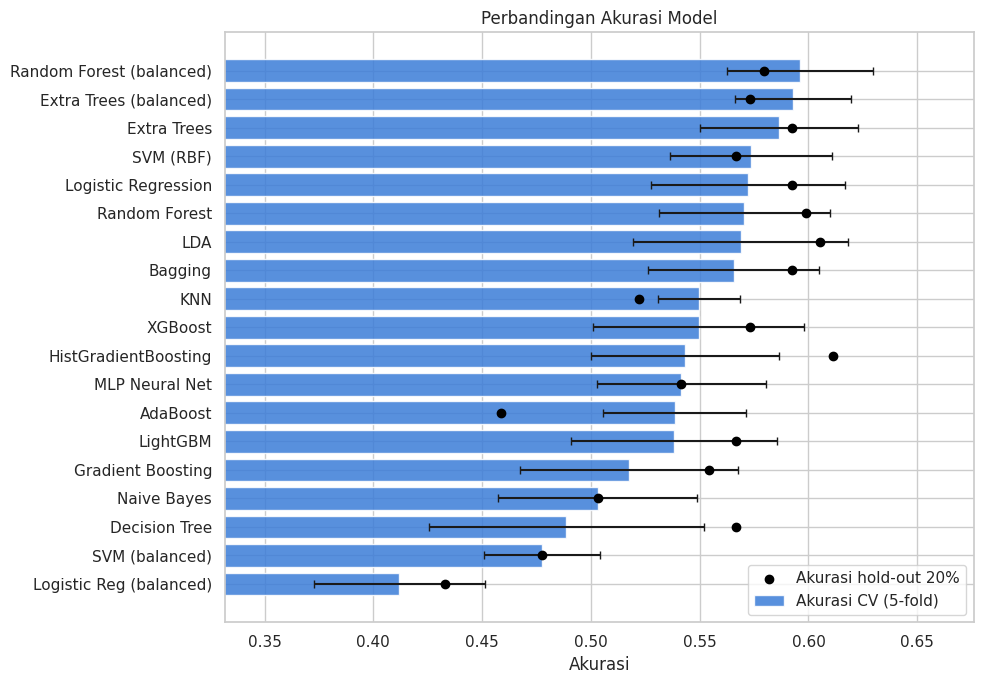

In [16]:
res = pd.DataFrame(results).sort_values(["CV_Acc", "CV_F1macro"], ascending=False).reset_index(drop=True)
res["Gap_Overfit"] = res["Train_Acc"] - res["CV_Acc"]
res.index = res.index + 1

print("A. Akurasi, kestabilan, dan indikator overfitting")
display(res[["Model", "CV_Acc", "CV_Std", "CV_F1macro", "Train_Acc", "Holdout_Acc", "Gap_Overfit", "Waktu_detik"]].round(4))
print("\nB. Metrik klasifikasi pada hold-out 20%")
display(res[["Model", "Holdout_Acc", "Holdout_BalAcc", "Precision_macro", "Recall_macro", "F1_macro", "F1_weighted", "Kappa", "QWK"]].round(4))

plot_df = res.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_df["Model"], plot_df["CV_Acc"], xerr=plot_df["CV_Std"], color="#3b7dd8", alpha=.85, capsize=3, label="Akurasi CV (5-fold)")
ax.scatter(plot_df["Holdout_Acc"], plot_df["Model"], color="black", zorder=3, label="Akurasi hold-out 20%")
ax.set_xlim(plot_df["CV_Acc"].min() - 0.08, plot_df["CV_Acc"].max() + 0.08)
ax.set_title("Perbandingan Akurasi Model")
ax.set_xlabel("Akurasi")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretasi tabel A (akurasi & *overfitting*):**
- Tiga teratas berdekatan: **Random Forest (balanced) CV 0.5961**, Extra Trees (balanced) (0.5929), dan Extra Trees (0.5865). Selisihnya kurang dari 1 poin, jauh di bawah simpangan baku CV (±2.7–3.6 poin), jadi pada dasarnya **setara**. SVM (0.5736), Logistic Regression (0.5721), dan Random Forest (0.5704) menyusul dalam jarak sekitar 2–3 poin.
- **Varian `balanced` untuk model linear/kernel justru merugikan akurasi**: Logistic Regression turun dari 0.5721 ke **0.4119** dan SVM dari 0.5736 ke **0.4775**. Bobot kelas membuat model sering menebak kelas langka sehingga banyak kelas besar (5 dan 6) salah tebak. Untuk model pohon, pembobotan memberi sedikit kenaikan (Random Forest +2.6 poin, Extra Trees +0.6 poin), tetapi masih dalam kisaran *noise* CV.
- **Model dengan CV terendah (tanpa pembobotan)** adalah Decision Tree (0.4887) dan Naive Bayes (0.5032). Decision Tree tunggal mudah menghafal data, sedangkan Naive Bayes mengasumsikan fitur saling bebas padahal data ini memiliki fitur yang saling berkorelasi (misalnya `fixed acidity` dengan `density` dan `pH`).
- ***Overfitting*:** model berbasis pohon dan KNN mencapai akurasi latih 1.00 (XGBoost 0.9952, Gradient Boosting 0.9583) tetapi CV hanya sekitar 0.52–0.60, sehingga gap-nya besar (0.40–0.46). Logistic Regression, LDA, MLP, AdaBoost, dan Naive Bayes hampir tanpa gap (< 0.06): stabil, tetapi tidak lebih akurat. Model *boosting* dengan parameter bawaan (XGBoost, LightGBM, HistGradientBoosting, Gradient Boosting) bahkan hanya mencapai CV 0.52–0.55, sehingga pada data sekecil ini tidak mengungguli Random Forest atau Extra Trees. Yang menentukan adalah skor CV, bukan akurasi latih.

**Interpretasi tabel B (metrik *hold-out*):**
- Akurasi *hold-out* tertinggi dimiliki HistGradientBoosting (0.6115, Kappa 0.3841, QWK 0.5881), diikuti LDA (0.6051) dan Random Forest (0.5987). Namun HistGradientBoosting hanya berada di peringkat 11 pada CV (0.5432), dan *hold-out* hanya 157 baris (satu sampel = 0.64 poin), jadi keunggulan di *hold-out* kemungkinan karena kebetulan dan jangan terlalu dipercaya.
- ***Balanced Accuracy*** tertinggi dimiliki Logistic Reg (balanced) 0.3879 dan Naive Bayes 0.3381, sedangkan kebanyakan model pohon berada di kisaran 0.27–0.29. Artinya model tersebut lebih sering menemukan kelas langka, tetapi harganya akurasi keseluruhan yang jauh lebih rendah (0.4331 dan 0.5032). Karena penilaian tugas ini adalah akurasi terhadap kunci jawaban, model tersebut tidak dipilih.
- Untuk hampir semua model, *F1 macro* (sekitar 0.27–0.31) jauh di bawah *F1 weighted* (sekitar 0.55–0.59 untuk model terbaik): model bagus pada kelas besar (5 dan 6) tetapi nyaris gagal pada kelas langka. MLP paling rendah pada *F1 macro* (0.1966).
- QWK (0.38–0.59) jauh lebih tinggi daripada Kappa biasa (0.16–0.38): banyak salah tebak hanya meleset satu tingkat kualitas, sehingga kesalahannya tidak terlalu jauh.

## **7. Evaluasi Lanjutan, *Tuning*, dan Pemilihan Model Terbaik**

### **7.1 *Hyperparameter tuning* (3 model teratas)**
**Penjelasan sintaks**
- `RandomizedSearchCV` mencoba kombinasi *hyperparameter* secara acak (`n_iter`) dan menilai tiap kombinasi dengan 5-*fold* CV. Lebih hemat waktu daripada mencoba semua kombinasi (*GridSearch*).
- Parameter *pipeline* ditulis `model__namaparameter` (awalan `model__` merujuk ke langkah bernama "model").
- Skor yang dioptimalkan: **akurasi** (karena penilaian tugas membandingkan prediksi dengan kunci jawaban).
- `VotingClassifier(voting="soft")` menggabungkan 3 model terbaik hasil tuning dengan merata-ratakan probabilitasnya (*ensemble*), seringkali lebih stabil daripada model tunggal.

In [17]:
PARAM_GRIDS = {
    "Random Forest": {"model__n_estimators": [300, 500, 800], "model__max_depth": [None, 8, 12, 16, 24],
                      "model__min_samples_split": [2, 4, 8], "model__min_samples_leaf": [1, 2, 3],
                      "model__max_features": ["sqrt", "log2", 0.5], "model__class_weight": [None, "balanced_subsample"]},
    "Extra Trees": {"model__n_estimators": [300, 500, 800], "model__max_depth": [None, 8, 12, 16, 24],
                    "model__min_samples_split": [2, 4, 8], "model__min_samples_leaf": [1, 2, 3],
                    "model__max_features": ["sqrt", "log2", 0.5], "model__class_weight": [None, "balanced"]},
    "Gradient Boosting": {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.03, 0.05, 0.1],
                          "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 0.85, 1.0],
                          "model__min_samples_leaf": [1, 3, 5]},
    "HistGradientBoosting": {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_iter": [100, 200, 300],
                             "model__max_leaf_nodes": [8, 15, 31], "model__min_samples_leaf": [5, 10, 20],
                             "model__l2_regularization": [0, 0.1, 1.0]},
    "SVM (RBF)": {"model__C": [0.5, 1, 3, 10, 30], "model__gamma": ["scale", 0.01, 0.05, 0.1, 0.3]},
    "KNN": {"model__n_neighbors": [5, 9, 15, 21, 31], "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "MLP Neural Net": {"model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)], "model__alpha": [1e-4, 1e-3, 1e-2],
                       "model__learning_rate_init": [1e-3, 5e-3]},
    "XGBoost": {"model__n_estimators": [200, 400], "model__learning_rate": [0.03, 0.05, 0.1],
                "model__max_depth": [3, 4, 6], "model__subsample": [0.7, 0.9], "model__colsample_bytree": [0.7, 0.9]},
    "LightGBM": {"model__n_estimators": [200, 400], "model__learning_rate": [0.03, 0.05, 0.1],
                 "model__num_leaves": [7, 15, 31], "model__min_child_samples": [5, 10, 20]},
}

top3 = [m for m in res["Model"] if m in PARAM_GRIDS][:3]
print("3 model yang di-tuning:", top3, "\n")

tuned = {}
for name in top3:
    t0 = time.time()
    n_iter = min(20, int(np.prod([len(v) for v in PARAM_GRIDS[name].values()])))
    search = RandomizedSearchCV(models[name], PARAM_GRIDS[name], n_iter=n_iter, cv=cv, scoring="accuracy",
                                random_state=SEED, n_jobs=1, refit=True)
    search.fit(X_tr, y_tr)
    tuned[name + " (tuned)"] = search.best_estimator_
    print(f"{name}: CV terbaik = {search.best_score_:.4f}  ({time.time()-t0:.0f} detik)")
    print("   param:", {k.replace('model__', ''): v for k, v in search.best_params_.items()})

voting = VotingClassifier(estimators=[(n.replace(" (tuned)", ""), m) for n, m in tuned.items()], voting="soft")
tuned["Voting Ensemble (top-3 tuned)"] = voting

3 model yang di-tuning: ['Extra Trees', 'SVM (RBF)', 'Logistic Regression'] 

Extra Trees: CV terbaik = 0.5896  (123 detik)
   param: {'n_estimators': 800, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 12, 'class_weight': 'balanced'}
SVM (RBF): CV terbaik = 0.5897  (12 detik)
   param: {'gamma': 0.01, 'C': 30}
Logistic Regression: CV terbaik = 0.5753  (1 detik)
   param: {'C': 100}


**Interpretasi:**
- Tiga model yang di-*tuning* adalah **Extra Trees, SVM (RBF), dan Logistic Regression**, yaitu tiga model teratas pada tabel perbandingan yang memiliki ruang pencarian parameter. Varian `balanced` dan Random Forest tidak ikut karena Random Forest berada di peringkat keempat di antara model yang bisa di-*tuning*. Pembobotan kelas sudah tercakup di pencarian Extra Trees lewat parameter `class_weight`.
- **Perubahan skor CV setelah *tuning*:**
  - Extra Trees: 0.5865 → **0.5896** (+0.3 poin)
  - SVM (RBF): 0.5736 → **0.5897** (+1.6 poin)
  - Logistic Regression: 0.5721 → **0.5753** (+0.3 poin)

  Kenaikannya kecil, jauh di bawah simpangan baku CV (±3–4 poin), jadi *tuning* hanya memberi perbaikan tipis.
- **Parameter terpilih:**
  - Extra Trees memilih `max_depth = 12` (kedalaman pohon dibatasi sehingga lebih sulit menghafal data), `max_features = 'log2'`, 800 pohon, dan `class_weight = 'balanced'`.
  - SVM memilih `C = 30` (penalti kesalahan besar, batas keputusan lebih rumit) dan `gamma = 0.01` (nilai kecil, sehingga batas keputusan halus).
  - Logistic Regression memilih `C = 100` (regularisasi sangat lemah).
- Skor di atas diperoleh pada *fold* yang sama dengan yang dipakai memilih parameter, sehingga cenderung **terlalu optimistis**. Pembuktian yang adil dilakukan pada langkah berikutnya, dengan membagi *fold* secara berbeda.

### **7.2 Perbandingan akhir**
**Penjelasan sintaks**
- Versi **sebelum *tuning***, **sesudah tuning**, dan **ensemble** (ditambah juara umum tahap 6 bila belum termasuk) dinilai ulang memakai pembagian CV yang *berbeda* (`random_state=SEED+1`), supaya skor tidak menguntungkan model yang kebetulan dipilih oleh `RandomizedSearchCV` pada pembagian lama.
- **Model terbaik** = akurasi CV tertinggi (jika sama, *F1 macro* tertinggi).

In [18]:
cv_eval = StratifiedKFold(5, shuffle=True, random_state=SEED + 1)
finalists = {n + " (default)": models[n] for n in top3}
overall_best = res.iloc[0]["Model"]          # model terbaik secara umum (bisa varian balanced yang tidak di-tuning)
if overall_best not in top3:
    finalists[overall_best + " (default)"] = models[overall_best]
finalists.update(tuned)

final_rows = [evaluate(n, m, cv_eval) for n, m in finalists.items()]
final = pd.DataFrame(final_rows).sort_values(["CV_Acc", "CV_F1macro"], ascending=False).reset_index(drop=True)
final.index = final.index + 1
display(final[["Model", "CV_Acc", "CV_Std", "CV_F1macro", "Train_Acc", "Holdout_Acc", "F1_macro", "Kappa", "QWK"]].round(4))

best_name = final.iloc[0]["Model"]
best_model = finalists[best_name]
print(f"\n>>> MODEL TERBAIK: {best_name}")

,Model,CV_Acc,CV_Std,CV_F1macro,Train_Acc,Holdout_Acc,F1_macro,Kappa,QWK
1,SVM (RBF) (default),0.5995,0.0442,0.2822,0.7260,0.5669,0.2725,0.3014,0.5122
2,Voting Ensemble (top-3 tuned),0.5962,0.0531,0.2682,0.8141,0.6115,0.2789,0.3589,0.5251
3,Extra Trees (tuned),0.5962,0.0400,0.2896,1.0000,0.5605,0.2734,0.2945,0.4753
4,Random Forest (balanced) (default),0.5899,0.0552,0.2671,1.0000,0.5796,0.2709,0.3097,0.4943
5,Extra Trees (default),0.5883,0.0515,0.2607,1.0000,0.5924,0.2920,0.3350,0.5011
6,SVM (RBF) (tuned),0.5866,0.0479,0.2631,0.6651,0.5796,0.2650,0.3079,0.5028
7,Logistic Regression (default),0.5818,0.0270,0.2657,0.6042,0.5924,0.2708,0.3320,0.5019
8,Logistic Regression (tuned),0.5785,0.0288,0.2977,0.6010,0.5860,0.2701,0.3273,0.4736



>>> MODEL TERBAIK: SVM (RBF) (default)


**Interpretasi:**
- Delapan kandidat dinilai ulang dengan pembagian *fold* yang berbeda (`random_state = SEED + 1`). **SVM (RBF) default** memiliki CV tertinggi (**0.5995**), disusul Voting Ensemble dan Extra Trees (tuned) yang sama-sama 0.5962, lalu Random Forest (balanced) 0.5899 dan Extra Trees default 0.5883.
- Seluruh kandidat berada pada rentang CV yang sempit (**0.5785–0.5995**, selisih hanya 2.1 poin), sedangkan simpangan baku CV 2.7–5.5 poin. Jadi perbedaan antar model **tidak signifikan secara statistik**: semuanya setara, dan model terbaik dipilih berdasarkan aturan skor CV tertinggi.
- **Pengaruh *tuning* pada *fold* baru tidak konsisten:**
  - Extra Trees: 0.5883 → 0.5962 (+0.8 poin)
  - SVM (RBF): 0.5995 → 0.5866 (**−1.3 poin**)
  - Logistic Regression: 0.5818 → 0.5785 (−0.3 poin)

  SVM hasil *tuning* justru lebih buruk daripada versi default, padahal pada langkah sebelumnya skornya tampak naik (0.5737 → 0.5897). Ini tanda bahwa *tuning* pada data sekecil ini ikut menyesuaikan diri dengan noise *fold* (*overfitting* pada hyperparameter), sehingga manfaatnya kecil dan tidak bisa diandalkan.
- ***Voting Ensemble*** memiliki hasil *hold-out* terbaik di antara kandidat (akurasi **0.6115**, Kappa **0.3589**, QWK **0.5251**), tetapi CV-nya sedikit di bawah SVM dan simpangan bakunya lebih besar (0.0531). *Hold-out* hanya 157 baris (satu sampel = 0.64 poin), jadi selisih akurasi 0.6115 vs 0.5669 setara sekitar 7 sampel dan tidak dipakai sebagai dasar pemilihan.
- **Perbandingan *overfitting*:** SVM memiliki akurasi latih 0.7260 vs CV 0.5995 (gap ≈ 0.13), sedangkan Extra Trees (tuned) memiliki akurasi latih 1.0000 vs CV 0.5962 (gap ≈ 0.40). Dengan CV yang setara, **SVM lebih tidak *overfit*** sehingga generalisasinya lebih meyakinkan.
- **Model terbaik: SVM (RBF) default** (`C = 3`, kernel RBF, dengan `StandardScaler`), dipilih karena skor CV tertinggi (0.5995) dan *gap overfitting* yang jauh lebih kecil daripada model berbasis pohon.

### **7.3 Evaluasi mendalam model terbaik**
**Penjelasan sintaks**
- `classification_report` memberi *precision* (ketepatan tebakan), *recall* (kemampuan menemukan kelas), dan *F1* (gabungan keduanya) **per kelas**; `support` = jumlah sampel kelas itu di *hold-out*.
- `confusion_matrix` = tabel tebakan vs kenyataan. Baris = kualitas asli, kolom = prediksi. Diagonal = tebakan benar. Versi kanan dinormalisasi per baris (= *recall* tiap kelas).
- `accuracy ±1` = persentase tebakan yang meleset paling banyak satu tingkat (relevan karena kualitas berurutan).
- `permutation_importance` mengacak satu fitur lalu melihat seberapa turun akurasi. Makin besar penurunannya, makin penting fitur itu (berlaku untuk model apa pun).

Akurasi hold-out : 0.5669
Akurasi ±1 tingkat: 0.9554
Cohen's Kappa    : 0.3014
Quadratic Kappa  : 0.5122

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.62      0.70      0.66        66
           6       0.53      0.58      0.55        62
           7       0.54      0.35      0.42        20
           8       0.00      0.00      0.00         3

    accuracy                           0.57       157
   macro avg       0.28      0.27      0.27       157
weighted avg       0.54      0.57      0.55       157



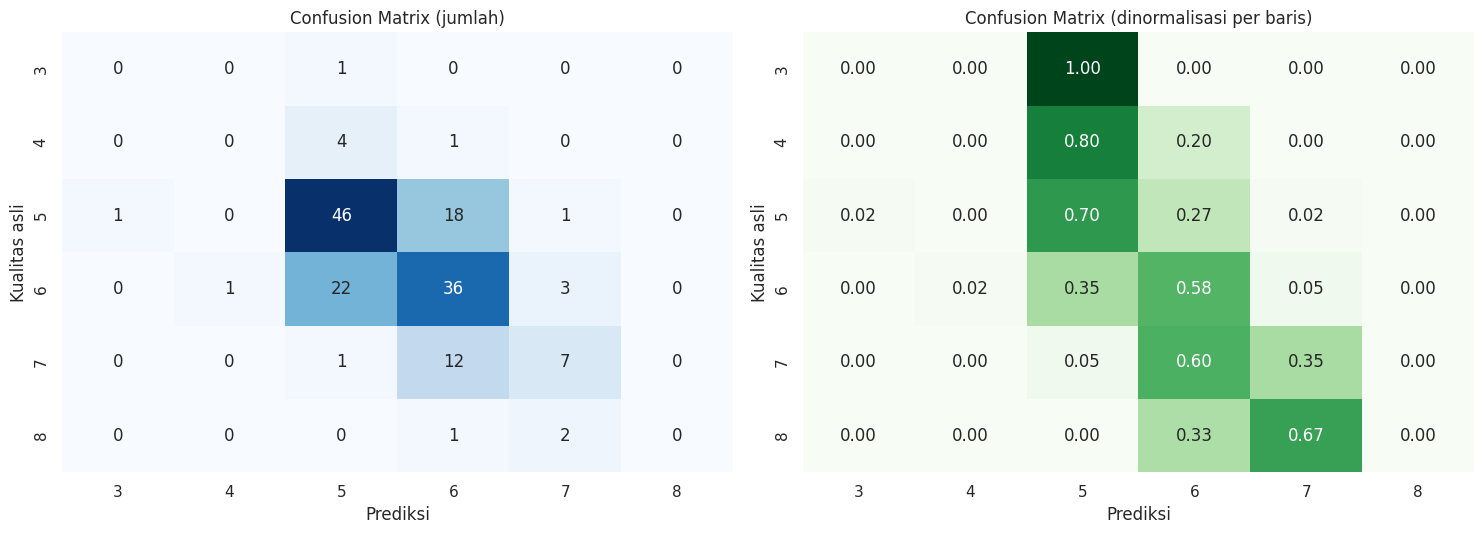

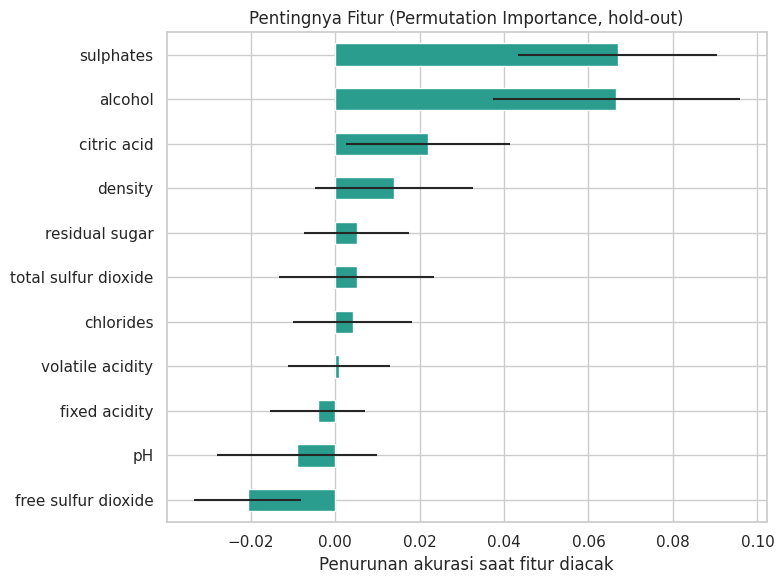

In [19]:
best_model.fit(X_tr, y_tr)
pred_val = best_model.predict(X_val)
labels_idx = list(range(len(CLASSES)))
names = [str(c) for c in CLASSES]

print(f"Akurasi hold-out : {accuracy_score(y_val, pred_val):.4f}")
print(f"Akurasi ±1 tingkat: {(np.abs(CLASSES[pred_val] - CLASSES[y_val]) <= 1).mean():.4f}")
print(f"Cohen's Kappa    : {cohen_kappa_score(y_val, pred_val):.4f}")
print(f"Quadratic Kappa  : {cohen_kappa_score(y_val, pred_val, weights='quadratic'):.4f}\n")
print(classification_report(y_val, pred_val, labels=labels_idx, target_names=names, zero_division=0))

cm = confusion_matrix(y_val, pred_val, labels=labels_idx)
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=axes[0], cbar=False)
axes[0].set_title("Confusion Matrix (jumlah)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=names, yticklabels=names, ax=axes[1], cbar=False)
axes[1].set_title("Confusion Matrix (dinormalisasi per baris)")
for ax in axes:
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Kualitas asli")
plt.tight_layout()
plt.show()

pi = permutation_importance(best_model, X_val, y_val, n_repeats=20, random_state=SEED, scoring="accuracy", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_val.columns).sort_values()
plt.figure(figsize=(8, 6))
imp.plot(kind="barh", xerr=pd.Series(pi.importances_std, index=X_val.columns)[imp.index], color="#2a9d8f")
plt.title("Pentingnya Fitur (Permutation Importance, hold-out)")
plt.xlabel("Penurunan akurasi saat fitur diacak")
plt.tight_layout()
plt.show()

**Interpretasi:**
- Akurasi *hold-out* model terbaik (SVM RBF) adalah **56.69%** (sekitar 89 dari 157 data uji benar). Sebagai pembanding, menebak selalu kelas terbanyak (kualitas 5, 66 dari 157 data) hanya menghasilkan akurasi sekitar 42%, sehingga model ini lebih baik sekitar **15 poin** daripada tebakan sederhana.
- **Akurasi ±1 tingkat = 95.54%**: sekitar 150 dari 157 prediksi hanya meleset paling banyak satu tingkat kualitas (misalnya kualitas 5 ditebak 6). Hanya sekitar 7 prediksi yang meleset dua tingkat atau lebih. Ini wajar karena kualitas bersifat berurutan dan kelas yang bersebelahan memiliki karakteristik kimia yang mirip.
- **Cohen's Kappa = 0.3014** (kesepakatan cukup/*fair*) dan **Quadratic Weighted Kappa = 0.5122** (kesepakatan *sedang/moderate*). QWK jauh lebih tinggi karena menghukum salah tebak yang jauh lebih berat daripada yang hanya meleset satu tingkat, dan mayoritas kesalahan model memang dekat.
- **Kinerja per kelas:**
  - **Kelas 5** paling baik: *precision* 0.62, *recall* 0.70, F1 0.66.
  - **Kelas 6** sedang: *precision* 0.53, *recall* 0.58, F1 0.55.
  - **Kelas 7** *recall* rendah: *precision* 0.54 tetapi *recall* hanya 0.35 (F1 0.42), artinya baru sekitar sepertiga anggur berkualitas 7 yang berhasil dikenali, sisanya kemungkinan besar ditebak sebagai kelas 6.
  - **Kelas 3, 4, dan 8** bernilai **0.00** untuk semua metrik. Model tidak berhasil memprediksi satu pun anggur dari kelas ini, yang totalnya hanya 9 dari 157 data uji (1, 5, dan 3 sampel). Contoh latih untuk kelas ini terlalu sedikit sehingga model tidak bisa mempelajarinya.
- **Macro avg (F1 = 0.27)** jauh lebih rendah daripada **weighted avg (F1 = 0.55)**. Macro menghitung semua kelas sama rata sehingga tertarik turun oleh tiga kelas langka yang bernilai 0, sedangkan weighted dipengaruhi oleh kelas 5 dan 6 yang jumlahnya dominan. Artinya model **cukup baik pada kelas mayoritas, tetapi tidak mampu mengenali kelas langka**.

## **8. Prediksi Data *Testing* dengan Model Terbaik**

**Penjelasan sintaks**
- Sampai tahap ini model hanya memakai 80% data. Untuk hasil akhir, model terbaik **dilatih ulang pada seluruh data *training* yang sudah bersih** (`fit(X_all, y_all)`): data lebih banyak = model lebih baik.
- `predict(X_test)` menghasilkan kode kelas (0..5); `le.inverse_transform` mengembalikannya ke skala kualitas asli.
- Format file mengikuti contoh: **hanya dua kolom `Id` dan `Quality`, pemisah titik koma (`;`)**, tanpa indeks (`index=False`).
- `joblib.dump` menyimpan model ke file, sesuai instruksi "simpan model yang anda buat".
- Beberapa pemeriksaan (*assert*) memastikan jumlah baris, urutan Id, dan tidak ada nilai kosong.

File hasil : hasilprediksi_025.csv  (286 baris)
Model      : model_wine_terbaik.joblib

Isi 5 baris pertama file hasil:


,Id,Quality
0,222,5
1,1514,5
2,417,5
3,754,5
4,516,6


,training (%),prediksi testing (%)
3,0.8,0.0
4,3.3,0.0
5,42.3,47.9
6,39.7,43.4
7,12.4,8.7
8,1.5,0.0


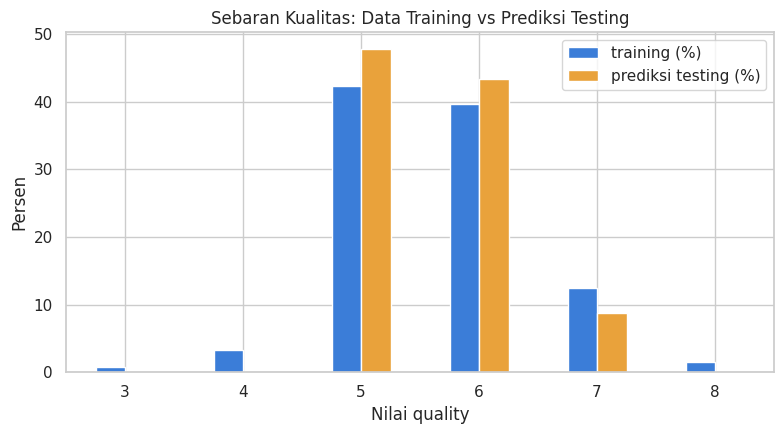

In [20]:
final_model = finalists[best_name]
final_model.fit(X_all, y_all)

pred_enc = final_model.predict(X_test)
pred_quality = le.inverse_transform(pred_enc)

submission = pd.DataFrame({"Id": test_ids, "Quality": pred_quality.astype(int)})

assert len(submission) == len(df_test), "Jumlah baris tidak sama dengan data testing"
assert submission["Id"].is_unique and submission["Quality"].notna().all()
if sample_sub is not None:
    assert list(submission["Id"]) == list(sample_sub["Id"]), "Urutan Id berbeda dengan file contoh"
    print("Urutan Id cocok dengan file contoh dosen.")

out_csv = DATA_DIR / f"hasilprediksi_{NIM3}.csv"
submission.to_csv(out_csv, sep=";", index=False)

out_model = DATA_DIR / "model_wine_terbaik.joblib"
joblib.dump({"model": final_model, "label_encoder": le, "features": list(X_all.columns), "use_fe": USE_FE}, out_model)

print(f"File hasil : {out_csv}  ({len(submission)} baris)")
print(f"Model      : {out_model}")
print("\nIsi 5 baris pertama file hasil:")
display(submission.head())

dist = pd.DataFrame({"training (%)": pd.Series(df_clean[TARGET]).value_counts(normalize=True).sort_index() * 100,
                     "prediksi testing (%)": submission["Quality"].value_counts(normalize=True).sort_index() * 100}).fillna(0).round(1)
display(dist)
dist.plot(kind="bar", figsize=(8, 4.5), color=["#3b7dd8", "#e9a23b"])
plt.title("Sebaran Kualitas: Data Training vs Prediksi Testing")
plt.xlabel("Nilai quality")
plt.ylabel("Persen")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretasi:**
- Model terbaik (SVM RBF) dilatih ulang pada **seluruh data *training* yang sudah bersih** (781 baris), lalu dipakai memprediksi **286 data *testing***. Hasilnya disimpan ke `hasilprediksi_025.csv` dan modelnya ke `model_wine_terbaik.joblib`.
- File hasil berisi dua kolom, `Id` dan `Quality`, dengan jumlah baris **286** sama dengan data *testing*. Urutan Id mengikuti data *testing* (222, 1514, 417, 754, 516, ...), sesuai format yang diminta dosen.
- **Sebaran prediksi:** kualitas 5 sebanyak **47.9%** (sekitar 137 sampel), kualitas 6 sebanyak **43.4%** (sekitar 124 sampel), dan kualitas 7 sebanyak **8.7%** (sekitar 25 sampel). Model **tidak memprediksi kelas 3, 4, dan 8**, padahal pada data *training* kelas tersebut berjumlah 5.6% (0.8% + 3.3% + 1.5%). Ini konsisten dengan hasil evaluasi: kelas langka memiliki precision dan recall 0 karena contoh latihnya terlalu sedikit.
- Dibanding data *training*, prediksi lebih condong ke kelas 5 (47.9% vs 42.3%) dan 6 (43.4% vs 39.7%), sedangkan kelas 7 lebih jarang diprediksi (8.7% vs 12.4%). Ini sejalan dengan recall kelas 7 yang rendah (0.35): sebagian anggur berkualitas 7 kemungkinan ditebak sebagai 6. Meski begitu, sebaran prediksi pada kelas 5–7 tetap mirip dengan data *training*, tanda bahwa hasilnya tidak menyimpang secara tidak wajar.
- Berdasarkan evaluasi, akurasi pada data *testing* diperkirakan sekitar **57–60%**, dengan sebagian besar kesalahan hanya meleset satu tingkat kualitas.

## Kesimpulan

Penelitian ini membangun model klasifikasi untuk memprediksi kualitas anggur (skala 3–8) dari 11 fitur kimiawi menggunakan 857 data *training*, lalu memprediksi 286 data *testing*. Setelah pembersihan data (76 baris duplikat dihapus sehingga tersisa 781 baris), sebanyak 19 model dari berbagai keluarga algoritma dibandingkan menggunakan 5-*fold cross-validation* dan *hold-out* 20%. Model terbaik adalah **SVM (RBF) dengan parameter bawaan**, dengan akurasi CV **0.5995** dan akurasi *hold-out* **0.5669**. Akurasi ini sekitar 15 poin di atas tebakan kelas mayoritas (≈42%), dan 95.54% prediksinya hanya meleset paling banyak satu tingkat kualitas. Namun, perbedaan antar model terbaik sangat kecil dibanding ketidakpastian pengukuran, sehingga tidak ada model yang unggul secara meyakinkan. Kelemahan utama model adalah ketidakmampuannya mengenali kelas langka (kualitas 3, 4, dan 8).

### Rincian temuan
**1. Data dan EDA**
- Data lengkap tanpa *missing value*. Duplikat baru terdeteksi (76 baris, 8.9%) setelah kolom `Id` dikeluarkan dari pemeriksaan, karena `Id` yang selalu unik menyembunyikan duplikat.
- Kelas target sangat tidak seimbang: kualitas 5 (42.3%) dan 6 (39.7%) mendominasi, sedangkan kualitas 3 hanya 0.8% dan kualitas 8 hanya 1.5% (rasio kelas terbesar : terkecil ≈ 60 : 1).
- Fitur yang paling berkorelasi dengan kualitas: `alcohol` (+0.47), `volatile acidity` (−0.43), dan `sulphates` (+0.26). Tidak ada korelasi yang melebihi 0.5, sehingga hubungan fitur–kualitas hanya lemah sampai sedang.
- Beberapa fitur sangat miring ke kanan (`chlorides` skew 6.09, `residual sugar` 4.54). Distribusi data *training* dan *testing* tidak berbeda nyata (semua *p-value* uji KS > 0.05).

**2. *Preprocessing***
- Duplikat dihapus agar skor *cross-validation* tidak bocor dan terlalu optimis. *Outlier* dipertahankan karena merupakan pengukuran kimia yang nyata.
- *Scaling* (`StandardScaler`) hanya dipakai untuk model yang peka skala. *Feature engineering* diuji tetapi **tidak dipakai** karena rata-rata kenaikan akurasinya hanya +0.0031, di bawah ambang 0.02 dan masih dalam *noise* CV.

**3. Pemodelan dan evaluasi**
- Model berbasis pohon (Random Forest, Extra Trees) mencapai akurasi latih 1.00 tetapi CV hanya ≈0.57–0.60, jadi mereka overfit. SVM jauh lebih stabil (gap latih–CV ≈ 0.13).
- Pembobotan kelas (`class_weight="balanced"`) merugikan akurasi model linear dan SVM (Logistic Regression 0.5721 → 0.4119, SVM 0.5736 → 0.4775), dan hanya memberi sedikit kenaikan pada model pohon.
- *Tuning hyperparameter* tidak memberi perbaikan yang andal: SVM hasil *tuning* justru lebih rendah (0.5866) daripada versi bawaan (0.5995) saat dinilai pada *fold* baru.
- Metrik model terbaik (*hold-out*): akurasi 0.5669, Cohen's Kappa 0.3014 (cukup), Quadratic Weighted Kappa 0.5122 (sedang), F1 macro 0.27, F1 weighted 0.55.
- Kinerja per kelas: kelas 5 (F1 0.66) dan kelas 6 (F1 0.55) cukup baik, kelas 7 lemah (recall 0.35), sedangkan kelas 3, 4, dan 8 bernilai 0.00.

**4. Hasil prediksi data *testing***
- File `hasilprediksi_025.csv` berisi 286 baris (`Id` dan `Quality`). Sebaran prediksi: kualitas 5 sebanyak 47.9%, kualitas 6 sebanyak 43.4%, dan kualitas 7 sebanyak 8.7%. Tidak ada prediksi kualitas 3, 4, atau 8.
- Perkiraan akurasi pada data *testing* sekitar 57–60%.

## **Keterbatasan**
- **Ketidakseimbangan kelas ekstrem.** Kelas 3, 4, dan 8 hanya memiliki 1–5 sampel di data uji, sehingga model tidak pernah memprediksinya dan metrik per kelasnya tidak bisa dinilai secara andal.
- **Data kecil.** Dengan 781 baris *training* dan hold-out 157 baris (satu sampel = 0.64 poin akurasi), skor *hold-out* berfluktuasi cukup besar. Selisih antar model teratas (± 2 poin) lebih kecil daripada simpangan baku CV (± 3–5 poin), sehingga pemilihan model terbaik bersifat tipis dan tidak signifikan secara statistik.
- **Batas informasi fitur.** Korelasi fitur dengan kualitas hanya lemah sampai sedang. Skor kualitas anggur juga cenderung subjektif sehingga ada batas akurasi yang wajar dicapai dari data kimia saja.
- **Pencarian *hyperparameter* terbatas.** Tuning memakai pencarian acak dengan jumlah iterasi kecil pada tiga model teratas, dan skornya cenderung optimistis karena dinilai pada *fold* yang sama.
- **Kemungkinan tumpang tindih data.** Sebanyak 45 baris *testing* identik dengan baris *training*, sehingga akurasi di data *testing* berpotensi sedikit lebih tinggi daripada estimasi CV.
- **Hasil bergantung pada lingkungan.** Perbedaan versi *library* dapat menggeser skor CV sekitar 1 poin dan mengubah model yang terpilih.

## **Saran**
1. **Menangani ketidakseimbangan kelas** dengan teknik *resampling* (misalnya SMOTE) yang diterapkan hanya pada data latih di dalam setiap *fold*, atau dengan pendekatan *cost-sensitive learning* yang lebih terarah.
2. **Menambah data**, terutama sampel kualitas rendah (3–4) dan tinggi (8), karena inilah yang paling membatasi kemampuan model.
3. **Memperlakukan kualitas sebagai data berurutan** dengan *ordinal classification* atau regresi lalu pembulatan, karena kesalahan bertetangga jauh lebih ringan daripada kesalahan jauh. Jika tujuan memungkinkan, kelas dapat digabung menjadi tiga tingkat (rendah ≤ 5, sedang 6, tinggi ≥ 7).
4. **Evaluasi lebih andal** dengan *repeated* atau *nested cross-validation* dan uji statistik antar model (misalnya *paired t-test* pada skor *fold* atau uji McNemar), supaya perbedaan antar model bisa dinilai signifikan atau tidak.
5. ***Tuning* lebih mendalam** pada XGBoost, LightGBM, dan SVM dengan jumlah iterasi lebih besar atau optimasi Bayesian, serta mencoba *stacking* dari model yang beragam.
6. **Memperbaiki fitur**, misalnya transformasi *log* pada fitur yang sangat miring (`chlorides`, `residual sugar`, `sulphates`) dan seleksi fitur untuk mengurangi multikolinearitas.